In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Premier League Data Analysis")
print("All libraries imported successfully!")


Premier League Data Analysis
All libraries imported successfully!


In [2]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print(df.head())
print(df.columns.tolist())
print("Dataset shape:", df.shape)

Saving soccer18-19.csv to soccer18-19.csv
  Div     Date      HomeTeam        AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  10/8/18    Man United       Leicester     2     1   H     1     0   H   
1  E0  11/8/18   Bournemouth         Cardiff     2     0   H     1     0   H   
2  E0  11/8/18        Fulham  Crystal Palace     0     2   A     0     1   A   
3  E0  11/8/18  Huddersfield         Chelsea     0     3   A     0     2   A   
4  E0  11/8/18     Newcastle       Tottenham     1     2   A     1     2   A   

   ... HST  AST  HF  AF  HC  AC  HY  AY  HR  AR  
0  ...   6    4  11   8   2   5   2   1   0   0  
1  ...   4    1  11   9   7   4   1   1   0   0  
2  ...   6    9   9  11   5   5   1   2   0   0  
3  ...   1    4   9   8   2   5   2   1   0   0  
4  ...   2    5  11  12   3   5   2   2   0   0  

[5 rows x 23 columns]
['Div', 'Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', '

In [3]:
# Keep only the columns needed for analysis
df = df.dropna(subset=["HomeTeam", "AwayTeam", "FTHG", "FTAG"]).copy()

# Convert goal columns to numbers
df["FTHG"] = pd.to_numeric(df["FTHG"], errors="coerce")
df["FTAG"] = pd.to_numeric(df["FTAG"], errors="coerce")
df = df.dropna(subset=["FTHG", "FTAG"])

# Calculate total goals
df["TotalGoals"] = df["FTHG"] + df["FTAG"]

# Calculate match outcomes
df["Result"] = df.apply(
    lambda row: "Home Win" if row["FTHG"] > row["FTAG"]
    else ("Away Win" if row["FTHG"] < row["FTAG"] else "Draw"),
    axis=1
)

print("Total matches:", len(df))
print("\nMatch outcomes:")
print(df["Result"].value_counts())

print("\nAverage goals per match:", round(df["TotalGoals"].mean(), 2))
print("Total goals scored:", int(df["TotalGoals"].sum()))

Total matches: 380

Match outcomes:
Result
Home Win    181
Away Win    128
Draw         71
Name: count, dtype: int64

Average goals per match: 2.82
Total goals scored: 1072


PREMIER LEAGUE DATA ANALYSIS
Dataset downloaded successfully!

First five rows:


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,E0,10/8/18,Man United,Leicester,2,1,H,1,0,H,...,6,4,11,8,2,5,2,1,0,0
1,E0,11/8/18,Bournemouth,Cardiff,2,0,H,1,0,H,...,4,1,11,9,7,4,1,1,0,0
2,E0,11/8/18,Fulham,Crystal Palace,0,2,A,0,1,A,...,6,9,9,11,5,5,1,2,0,0
3,E0,11/8/18,Huddersfield,Chelsea,0,3,A,0,2,A,...,1,4,9,8,2,5,2,1,0,0
4,E0,11/8/18,Newcastle,Tottenham,1,2,A,1,2,A,...,2,5,11,12,3,5,2,2,0,0



Dataset shape: (380, 23)

Column names:
['Div', 'Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 23 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Div       380 non-null    object
 1   Date      380 non-null    object
 2   HomeTeam  380 non-null    object
 3   AwayTeam  380 non-null    object
 4   FTHG      380 non-null    int64 
 5   FTAG      380 non-null    int64 
 6   FTR       380 non-null    object
 7   HTHG      380 non-null    int64 
 8   HTAG      380 non-null    int64 
 9   HTR       380 non-null    object
 10  Referee   380 non-null    object
 11  HS        380 non-null    int64 
 12  AS        380 non-null    int64 
 13  HST       380 non-null    int64 
 14  AST       380 non-null    int64 
 15  HF        

/tmp/ipykernel_568/2617206859.py:73: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(


,Matches
Result,
Home Win,181
Away Win,128
Draw,71


...


TOP 5 TEAMS:


,Team,Played,Wins,Draws,Losses,Goals For,Goals Against,Goal Difference,Points
Position,,,,,,,,,
1,Man City,38,32,2,4,95,23,72,98
2,Liverpool,38,30,7,1,89,22,67,97
3,Chelsea,38,21,9,8,63,39,24,72
4,Tottenham,38,23,2,13,67,39,28,71
5,Arsenal,38,21,7,10,73,51,22,70



TOP 5 GOAL-SCORING TEAMS:


,Team,Goals For
Position,,
1,Man City,95
2,Liverpool,89
5,Arsenal,73
4,Tottenham,67
6,Man United,65



HOME WINS: 181
AWAY WINS: 128
DRAWS: 71
HOME GOALS: 596
AWAY GOALS: 476


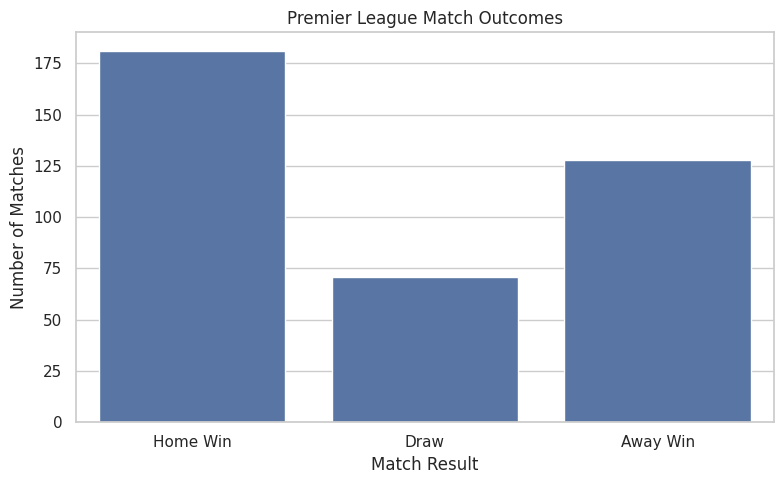

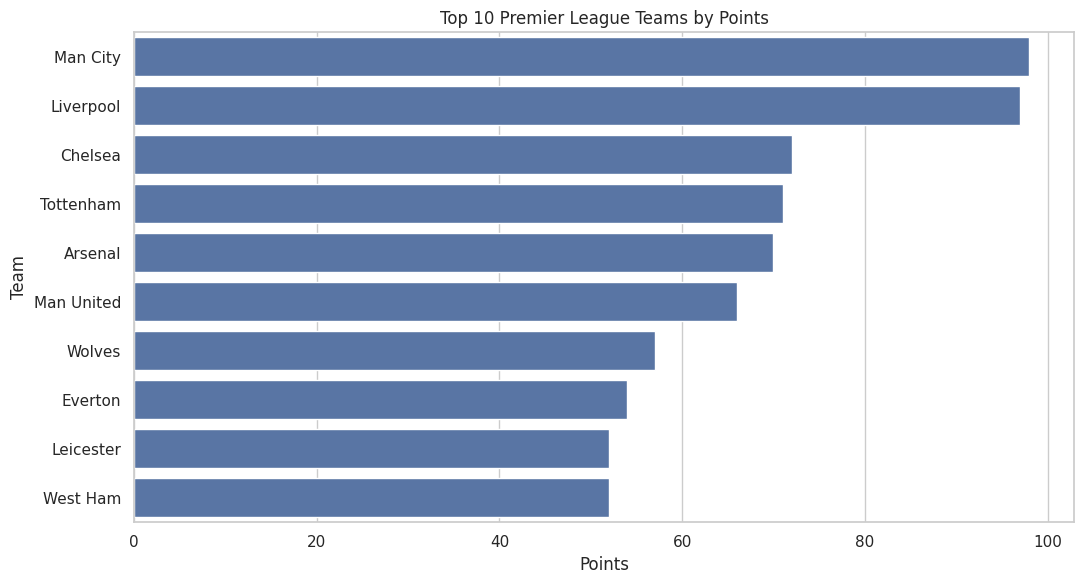

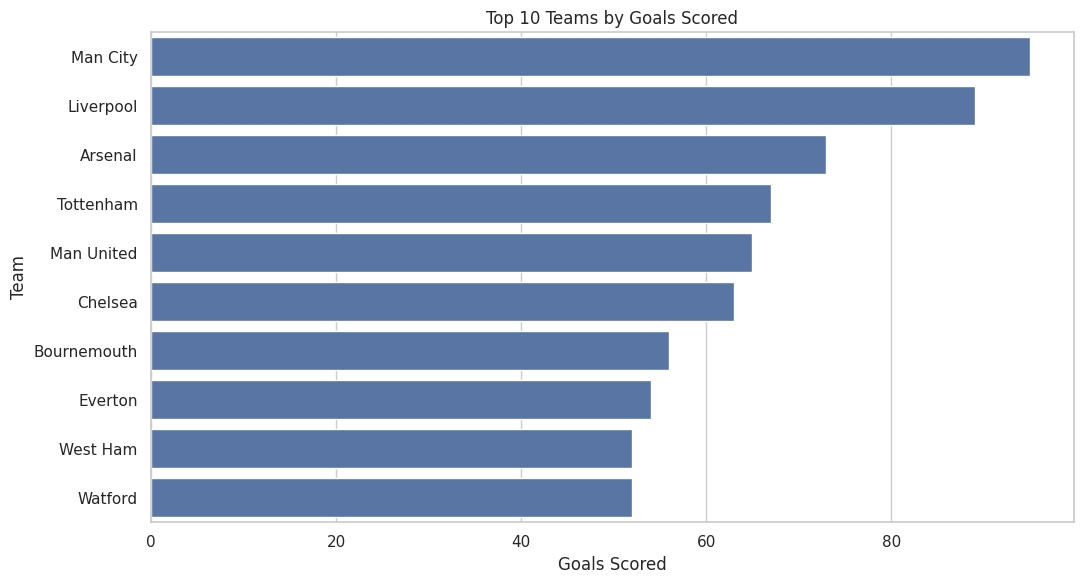

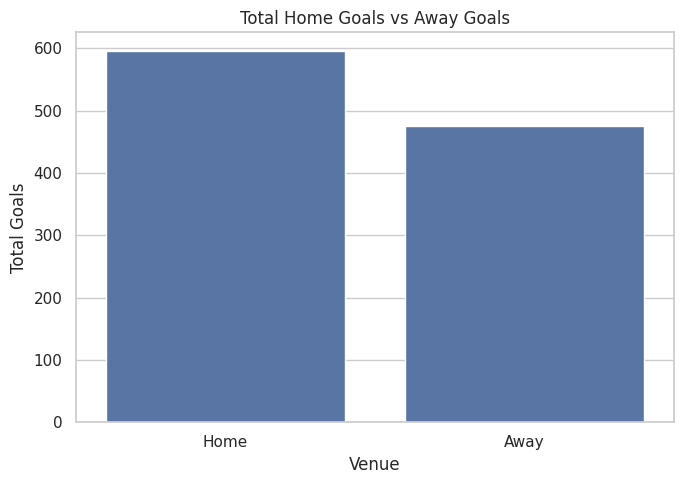

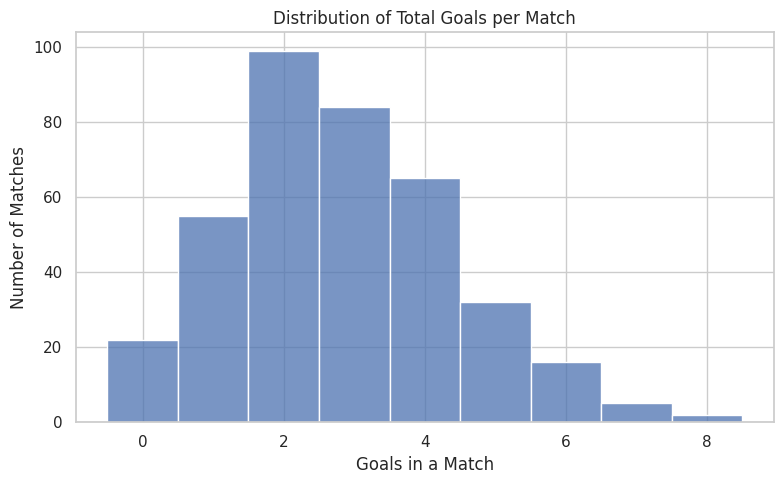

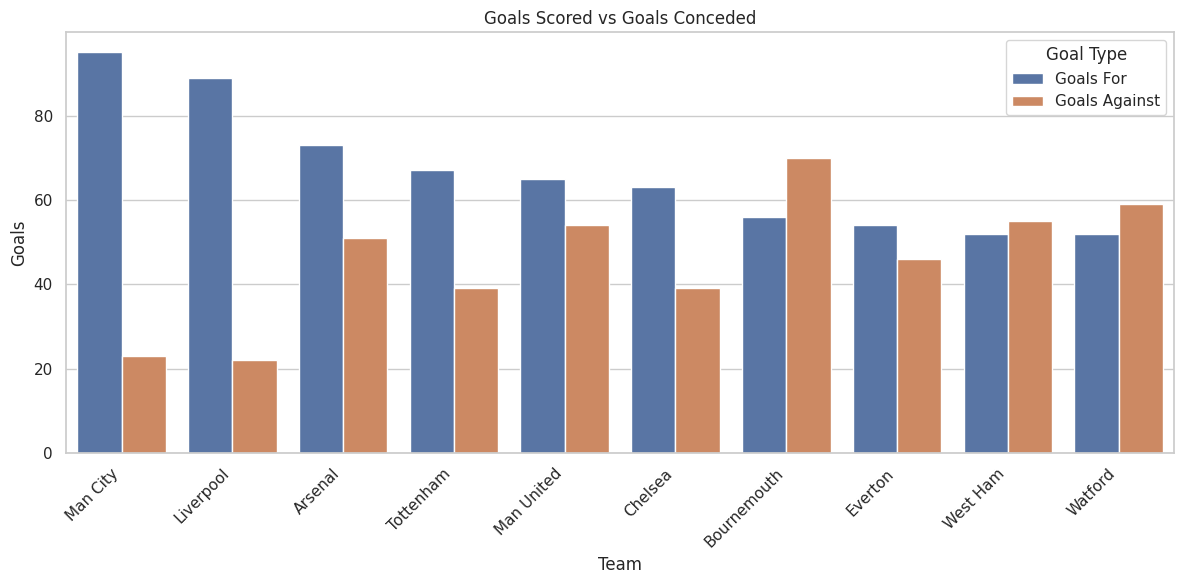


AVERAGE SHOTS PER MATCH
Home shots: 14.13
Away shots: 11.14
Home shots on target: 4.78
Away shots on target: 3.93

Saved files:
1. cleaned_premier_league.csv
2. premier_league_table.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT CONCLUSIONS
1. Total matches analyzed: 380
2. Total goals scored: 1072
3. Average goals per match: 2.82
4. Home wins: 181
5. Away wins: 128
6. Draws: 71
7. Top team by calculated points: Man City (98 points)
8. Most goals scored: Man City (95 goals)
9. Fewest goals conceded: Liverpool (22 goals)

Project completed successfully!


In [5]:
# ==========================================================
# PROJECT: PREMIER LEAGUE DATA ANALYSIS (2018-2019)
# Tools: Python, Pandas, Matplotlib, Seaborn
# ==========================================================

# STEP 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

print("PREMIER LEAGUE DATA ANALYSIS")
print("=" * 50)

# STEP 2: Load the dataset
url = (
    "https://raw.githubusercontent.com/"
    "itgdata/English-Premier-League-2018-2019/"
    "main/soccer18-19.csv"
)

try:
    df = pd.read_csv(url)
    print("Dataset downloaded successfully!")
except Exception:
    print("Automatic download failed.")
    print("Please upload soccer18-19.csv from your computer.")
    from google.colab import files
    uploaded = files.upload()
    filename = next(
        name for name in uploaded
        if name.lower().endswith(".csv")
    )
    df = pd.read_csv(filename)

# STEP 3: Explore the dataset
print("\nFirst five rows:")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# STEP 4: Clean the dataset
df.columns = df.columns.str.strip()

required_columns = [
    "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Dataset is missing columns: {missing_columns}"
    )

df = df.drop_duplicates().copy()

df["Date"] = pd.to_datetime(
    df["Date"], dayfirst=True, errors="coerce"
)

for col in ["FTHG", "FTAG"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]
).copy()

df = df[
    (df["FTHG"] >= 0) &
    (df["FTAG"] >= 0) &
    (df["FTHG"] % 1 == 0) &
    (df["FTAG"] % 1 == 0)
].copy()

df["FTHG"] = df["FTHG"].astype(int)
df["FTAG"] = df["FTAG"].astype(int)

print("\nCleaned dataset shape:", df.shape)
print("Missing values in required columns:",
      df[required_columns].isnull().sum().sum())

# STEP 5: Calculate match statistics
df["TotalGoals"] = df["FTHG"] + df["FTAG"]

df["Result"] = "Draw"
df.loc[df["FTHG"] > df["FTAG"], "Result"] = "Home Win"
df.loc[df["FTHG"] < df["FTAG"], "Result"] = "Away Win"

print("\nTOTAL MATCHES:", len(df))
print("TOTAL GOALS:", df["TotalGoals"].sum())
print("AVERAGE GOALS PER MATCH:",
      round(df["TotalGoals"].mean(), 2))

print("\nMatch results:")
display(df["Result"].value_counts().to_frame("Matches"))

# STEP 6: Build the league table
teams = sorted(
    set(df["HomeTeam"]).union(set(df["AwayTeam"]))
)

rows = []

for team in teams:
    home = df[df["HomeTeam"] == team]
    away = df[df["AwayTeam"] == team]

    played = len(home) + len(away)

    wins = (
        (home["FTHG"] > home["FTAG"]).sum()
        + (away["FTAG"] > away["FTHG"]).sum()
    )

    draws = (
        (home["FTHG"] == home["FTAG"]).sum()
        + (away["FTHG"] == away["FTAG"]).sum()
    )

    losses = played - wins - draws

    goals_for = home["FTHG"].sum() + away["FTAG"].sum()
    goals_against = home["FTAG"].sum() + away["FTHG"].sum()

    points = wins * 3 + draws

    rows.append({
        "Team": team,
        "Played": played,
        "Wins": int(wins),
        "Draws": int(draws),
        "Losses": int(losses),
        "Goals For": int(goals_for),
        "Goals Against": int(goals_against),
        "Goal Difference": int(goals_for - goals_against),
        "Points": int(points)
    })

league = pd.DataFrame(rows)

league = league.sort_values(
    ["Points", "Goal Difference", "Goals For"],
    ascending=False
).reset_index(drop=True)

league.index = league.index + 1
league.index.name = "Position"

print("\nPREMIER LEAGUE TABLE")
display(league)

print("\nTOP 5 TEAMS:")
display(league.head(5))

# STEP 7: Top teams by total goals
print("\nTOP 5 GOAL-SCORING TEAMS:")
display(
    league.nlargest(5, "Goals For")[["Team", "Goals For"]]
)

# STEP 8: Home versus away performance
home_wins = int((df["FTHG"] > df["FTAG"]).sum())
away_wins = int((df["FTHG"] < df["FTAG"]).sum())
draws = int((df["FTHG"] == df["FTAG"]).sum())

print("\nHOME WINS:", home_wins)
print("AWAY WINS:", away_wins)
print("DRAWS:", draws)

print("HOME GOALS:", int(df["FTHG"].sum()))
print("AWAY GOALS:", int(df["FTAG"].sum()))

# STEP 9: Chart 1 - Match outcomes
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Result",
    order=["Home Win", "Draw", "Away Win"]
)
plt.title("Premier League Match Outcomes")
plt.xlabel("Match Result")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

# STEP 10: Chart 2 - Top 10 teams by points
top_points = league.head(10).reset_index()

plt.figure(figsize=(11, 6))
sns.barplot(
    data=top_points,
    x="Points",
    y="Team"
)
plt.title("Top 10 Premier League Teams by Points")
plt.xlabel("Points")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

# STEP 11: Chart 3 - Top 10 teams by goals
top_goals = league.nlargest(10, "Goals For")

plt.figure(figsize=(11, 6))
sns.barplot(
    data=top_goals,
    x="Goals For",
    y="Team"
)
plt.title("Top 10 Teams by Goals Scored")
plt.xlabel("Goals Scored")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

# STEP 12: Chart 4 - Home and away goals
goal_comparison = pd.DataFrame({
    "Venue": ["Home", "Away"],
    "Goals": [df["FTHG"].sum(), df["FTAG"].sum()]
})

plt.figure(figsize=(7, 5))
sns.barplot(
    data=goal_comparison,
    x="Venue",
    y="Goals"
)
plt.title("Total Home Goals vs Away Goals")
plt.xlabel("Venue")
plt.ylabel("Total Goals")
plt.tight_layout()
plt.show()

# STEP 13: Chart 5 - Goals per match
plt.figure(figsize=(8, 5))
sns.histplot(
    df["TotalGoals"],
    discrete=True,
    kde=False
)
plt.title("Distribution of Total Goals per Match")
plt.xlabel("Goals in a Match")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

# STEP 14: Chart 6 - Goals scored and conceded
goal_data = league.nlargest(10, "Goals For").melt(
    id_vars="Team",
    value_vars=["Goals For", "Goals Against"],
    var_name="Goal Type",
    value_name="Goals"
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=goal_data,
    x="Team",
    y="Goals",
    hue="Goal Type"
)
plt.title("Goals Scored vs Goals Conceded")
plt.xlabel("Team")
plt.ylabel("Goals")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# STEP 15: Optional analysis of shots, if available
if {"HS", "AS", "HST", "AST"}.issubset(df.columns):
    for col in ["HS", "AS", "HST", "AST"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    print("\nAVERAGE SHOTS PER MATCH")
    print("Home shots:", round(df["HS"].mean(), 2))
    print("Away shots:", round(df["AS"].mean(), 2))
    print("Home shots on target:", round(df["HST"].mean(), 2))
    print("Away shots on target:", round(df["AST"].mean(), 2))
else:
    print("\nShot statistics are not available in this dataset.")

# STEP 16: Save output files
df.to_csv("cleaned_premier_league.csv", index=False)
league.to_csv("premier_league_table.csv")

print("\nSaved files:")
print("1. cleaned_premier_league.csv")
print("2. premier_league_table.csv")

# STEP 17: Download the output files in Google Colab
from google.colab import files

files.download("cleaned_premier_league.csv")
files.download("premier_league_table.csv")

# STEP 18: Generate conclusions from the data
print("\n" + "=" * 50)
print("PROJECT CONCLUSIONS")
print("=" * 50)

print(f"1. Total matches analyzed: {len(df)}")
print(f"2. Total goals scored: {df['TotalGoals'].sum()}")
print(f"3. Average goals per match: {df['TotalGoals'].mean():.2f}")
print(f"4. Home wins: {home_wins}")
print(f"5. Away wins: {away_wins}")
print(f"6. Draws: {draws}")

if len(league) > 0:
    champion = league.iloc[0]
    print(
        f"7. Top team by calculated points: {champion['Team']} "
        f"({champion['Points']} points)"
    )

    best_attack = league.loc[league["Goals For"].idxmax()]
    print(
        f"8. Most goals scored: {best_attack['Team']} "
        f"({best_attack['Goals For']} goals)"
    )

    best_defence = league.loc[league["Goals Against"].idxmin()]
    print(
        f"9. Fewest goals conceded: {best_defence['Team']} "
        f"({best_defence['Goals Against']} goals)"
    )

print("\nProject completed successfully!")